# Deteksi Penipuan Transaksi Kartu Kredit

Notebook ini mengeksplorasi data transaksi yang sangat tidak seimbang dan membandingkan pendekatan klasifikasi terawasi dengan deteksi anomali.

## 1. Import library dan memuat data

Memuat pustaka untuk pengolahan data, visualisasi, pemodelan, dan evaluasi. File `creditcard.csv` dibaca dari folder kerja notebook.

In [3]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("creditcard.csv")
data = pd.read_csv(DATA_PATH)
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Melihat ukuran dan kolom data

Memastikan jumlah transaksi, jumlah fitur, dan nama kolom yang tersedia sebelum analisis lebih lanjut.

In [13]:
print(f"Ukuran dataset: {data.shape[0]:,} baris dan {data.shape[1]} kolom")
print("Nama kolom:")
print(data.columns.tolist())
data.head()

Ukuran dataset: 284,807 baris dan 31 kolom
Nama kolom:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Memeriksa struktur dataset

Melihat tipe data dan jumlah nilai terisi untuk setiap kolom, termasuk memastikan label target `Class` tersedia.

In [14]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

## 4. Melihat statistik deskriptif

Meninjau rentang, rata-rata, dan sebaran nilai agar skala fitur serta kemungkinan nilai ekstrem terlihat.

In [15]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


## 5. Memeriksa nilai yang hilang

Menghitung nilai kosong pada tiap fitur. Dataset ini umumnya sudah lengkap, tetapi pemeriksaan ini membantu mendeteksi data yang perlu ditangani.

In [16]:
data.isnull().sum().sort_values(ascending=False).head(10)

Time    0
V1      0
V2      0
V3      0
V4      0
V5      0
V6      0
V7      0
V8      0
V9      0
dtype: int64

## 6. Mengukur ketimpangan kelas

Menghitung jumlah dan persentase transaksi normal (`Class = 0`) serta fraud (`Class = 1`) untuk memahami ketimpangan label.

In [17]:
class_counts = data["Class"].value_counts().sort_index()
class_percentages = data["Class"].value_counts(normalize=True).sort_index() * 100

pd.DataFrame({"Jumlah transaksi": class_counts, "Persentase (%)": class_percentages}).rename(index={0: "Normal", 1: "Fraud"})

,Jumlah transaksi,Persentase (%)
Class,,
Normal,284315,99.827251
Fraud,492,0.172749


## 7. Memvisualisasikan jumlah transaksi

Grafik batang memperlihatkan perbedaan jumlah kelas secara langsung; fraud yang sedikit menjadi alasan untuk tidak mengandalkan akurasi saja.

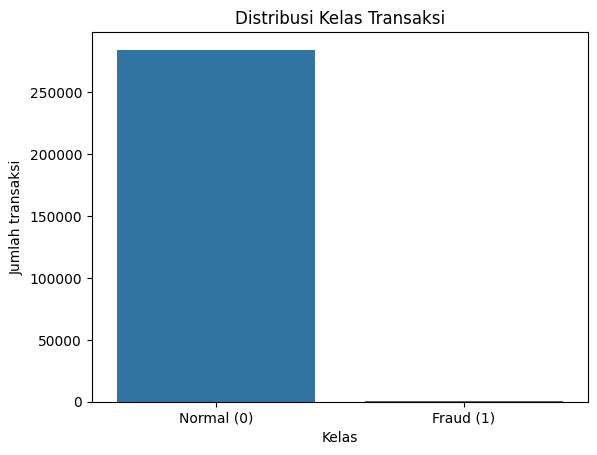

In [18]:
sns.countplot(data=data, x="Class")
plt.xticks([0, 1], ["Normal (0)", "Fraud (1)"])
plt.title("Distribusi Kelas Transaksi")
plt.xlabel("Kelas")
plt.ylabel("Jumlah transaksi")
plt.show()

## 8. Membagi data untuk pelatihan dan pengujian

Memisahkan fitur dari target `Class`. Opsi `stratify=y` menjaga proporsi fraud pada kedua bagian data.

In [4]:
X = data.drop(columns="Class")
y = data["Class"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Data latih: {len(X_train):,} transaksi")
print(f"Data uji: {len(X_test):,} transaksi")
print(f"Fraud pada data uji: {y_test.sum():,}")

Data latih: 227,845 transaksi
Data uji: 56,962 transaksi
Fraud pada data uji: 98


## 9. Membuat model baseline

Model ini selalu memprediksi kelas mayoritas. Hasilnya menjadi pembanding dan menunjukkan bagaimana akurasi dapat menutupi kegagalan mendeteksi fraud.

In [5]:
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

print(classification_report(y_test, baseline_predictions, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56962
   macro avg       0.50      0.50      0.50     56962
weighted avg       1.00      1.00      1.00     56962



## 10. Melatih Logistic Regression

Model terawasi ini memakai `class_weight="balanced"` agar kesalahan pada kelas fraud yang langka mendapat bobot lebih besar. Standardisasi dilakukan dalam pipeline.

In [6]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
)
logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)
logistic_scores = logistic_model.predict_proba(X_test)[:, 1]
print("Model Logistic Regression berhasil dilatih.")

Model Logistic Regression berhasil dilatih.


## 11. Mengukur kinerja Logistic Regression

Laporan klasifikasi merangkum precision, recall, dan F1. ROC-AUC dan PR-AUC mengevaluasi skor model; PR-AUC sangat berguna ketika fraud jarang.

In [7]:
print("Evaluasi Logistic Regression")
print(classification_report(y_test, logistic_predictions, target_names=["Normal", "Fraud"], zero_division=0))
print(f"ROC-AUC: {roc_auc_score(y_test, logistic_scores):.4f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test, logistic_scores):.4f}")

Evaluasi Logistic Regression
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

ROC-AUC: 0.9721
PR-AUC (Average Precision): 0.7190


## 12. Membaca confusion matrix

Matriks ini menunjukkan jumlah transaksi normal dan fraud yang diprediksi benar maupun keliru, termasuk alarm palsu dan fraud yang terlewat.

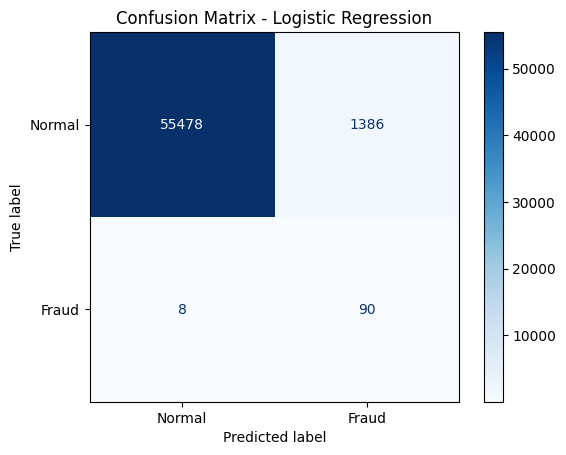

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["Normal", "Fraud"],
    cmap="Blues",
    values_format="d",
)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

## 13. Meninjau kurva Precision-Recall

Kurva ini memperlihatkan kompromi antara precision dan recall pada berbagai ambang prediksi, sehingga ambang dapat dipilih sesuai kebutuhan deteksi.

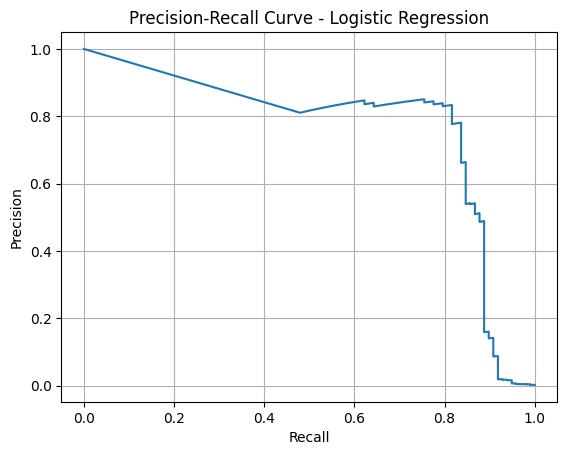

In [9]:
precision, recall, thresholds = precision_recall_curve(y_test, logistic_scores)

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.grid(True)
plt.show()

## 14. Melatih Isolation Forest

Isolation Forest dilatih hanya menggunakan transaksi normal agar model belajar pola umum lalu menandai pola yang menyimpang sebagai anomali.

In [10]:
normal_transactions = X_train.loc[y_train == 0]
normal_sample = normal_transactions.sample(
    n=min(50_000, len(normal_transactions)),
    random_state=42,
)

isolation_model = make_pipeline(
    StandardScaler(),
    IsolationForest(
        n_estimators=100,
        contamination=float(y_train.mean()),
        random_state=42,
        n_jobs=-1,
    ),
)
isolation_model.fit(normal_sample)
print(f"Isolation Forest dilatih pada {len(normal_sample):,} transaksi normal.")

Isolation Forest dilatih pada 50,000 transaksi normal.


## 15. Mengevaluasi deteksi anomali

Label `-1` dari Isolation Forest diubah menjadi kelas fraud. Precision, recall, dan F1 kemudian dihitung dengan test set yang sama agar hasil model bisa dibandingkan.

In [11]:
# Isolation Forest memberi label -1 untuk anomali dan 1 untuk transaksi normal.
isolation_predictions = (isolation_model.predict(X_test) == -1).astype(int)

print("Evaluasi Isolation Forest")
print(classification_report(y_test, isolation_predictions, target_names=["Normal", "Fraud"], zero_division=0))
print(f"Precision fraud: {precision_score(y_test, isolation_predictions, zero_division=0):.4f}")
print(f"Recall fraud: {recall_score(y_test, isolation_predictions, zero_division=0):.4f}")
print(f"F1 fraud: {f1_score(y_test, isolation_predictions, zero_division=0):.4f}")

Evaluasi Isolation Forest
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.19      0.26      0.22        98

    accuracy                           1.00     56962
   macro avg       0.60      0.63      0.61     56962
weighted avg       1.00      1.00      1.00     56962

Precision fraud: 0.1923
Recall fraud: 0.2551
F1 fraud: 0.2193


## 16. Membandingkan model

Tabel merangkum precision, recall, F1 untuk kelas fraud, serta PR-AUC untuk model yang menghasilkan skor probabilitas. Nilai PR-AUC Isolation Forest dikosongkan karena tahap ini memakai label anomali, bukan skor probabilitas.

In [12]:
comparison = pd.DataFrame(
    {
        "Precision Fraud": [
            precision_score(y_test, logistic_predictions, zero_division=0),
            precision_score(y_test, isolation_predictions, zero_division=0),
        ],
        "Recall Fraud": [
            recall_score(y_test, logistic_predictions, zero_division=0),
            recall_score(y_test, isolation_predictions, zero_division=0),
        ],
        "F1 Fraud": [
            f1_score(y_test, logistic_predictions, zero_division=0),
            f1_score(y_test, isolation_predictions, zero_division=0),
        ],
        "PR-AUC": [average_precision_score(y_test, logistic_scores), float("nan")],
    },
    index=["Logistic Regression", "Isolation Forest"],
)
comparison

,Precision Fraud,Recall Fraud,F1 Fraud,PR-AUC
Logistic Regression,0.060976,0.918367,0.114358,0.718971
Isolation Forest,0.192308,0.255102,0.219298,NaN
